# Pronóstico del saldo de financiaciones con tarjeta de crédito en Argentina
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PJUAREZZ/pronostico-saldo-tarjetas-credito-ar/blob/main/proyecto_integrador.ipynb)

**Proyecto Final Integrador** – Diplomado en Ciencia de Datos y Análisis Avanzado (Centro de e-Learning UTN BA)
**Autor:** Juárez, Pablo Nicolás

Notebook único y reproducible que sigue las fases de **CRISP-DM**:

| Fase | Sección del notebook |
|---|---|
| 1. Comprensión del negocio | Sección 0 (objetivo y KPI) |
| 2. Comprensión de los datos | Secciones 1 y 2 (descarga, calidad, EDA) |
| 3. Preparación de datos | Sección 3 (variables y control de fuga de información) |
| 4. Modelado | Secciones 4 y 5 (baselines y modelos) |
| 5. Evaluación | Secciones 5 y 6 (walk-forward, métricas, Diebold-Mariano) |
| 6. Despliegue (propuesta) | Sección 6 (pronóstico final) |

**Variable objetivo:** logaritmo del saldo mensual **nominal**; las métricas (MAPE, MAE, RMSE) se reportan en pesos nominales, revirtiendo el logaritmo.
**Reproducibilidad:** los datos se descargan de la API pública del BCRA con fecha de corte fija (`FECHA_CORTE`), por lo que se obtienen los mismos resultados del informe. Las cifras citadas en los textos corresponden a la corrida de octubre de 2026.

## 0. Configuración

In [1]:
import os
os.makedirs("data", exist_ok=True)       # datos descargados y base de modelado
os.makedirs("results", exist_ok=True)    # tablas y gráficos generados

# Fecha de corte de la descarga (para reproducir el informe). Para actualizar la serie, poner la fecha de hoy.
FECHA_CORTE = "2026-10-06"

## 1. Descarga de la serie objetivo (BCRA, idVariable 115)
Saldo diario de *Préstamos mediante tarjeta de crédito otorgados al sector privado*, en millones de pesos. Se guarda el dato crudo en `data/`.

In [2]:
import requests, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import urllib3
from statsmodels.graphics.tsaplots import plot_acf

urllib3.disable_warnings()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ID_VARIABLE = 115
BASE_URL = f"https://api.bcra.gob.ar/estadisticas/v4.0/Monetarias/{ID_VARIABLE}"

In [3]:
# ---------- 1. DESCARGA ----------
def descargar_serie(desde="2002-01-01", hasta=None, limit=3000):
    hasta = hasta or FECHA_CORTE
    filas, offset = [], 0
    while True:
        params = {"desde": desde, "hasta": hasta, "limit": limit, "offset": offset}
        try:
            r = requests.get(BASE_URL, params=params, timeout=60)
        except requests.exceptions.SSLError:
            r = requests.get(BASE_URL, params=params, timeout=60, verify=False)
        r.raise_for_status()
        data = r.json()
        results = data["results"]
        if results and isinstance(results[0], dict) and "detalle" in results[0]:
            bloque = results[0]["detalle"]
        else:
            bloque = results
        if not bloque:
            break
        filas.extend(bloque)
        total = data.get("metadata", {}).get("resultset", {}).get("count", len(filas))
        offset += limit
        if offset >= total:
            break
        time.sleep(0.5)
    df = pd.DataFrame(filas)[["fecha", "valor"]]
    df["fecha"] = pd.to_datetime(df["fecha"])
    return df.sort_values("fecha").drop_duplicates("fecha").reset_index(drop=True)

In [4]:
print("Descargando serie del BCRA...")
diario = descargar_serie()
diario.to_csv("data/bcra_tc_diario_raw.csv", index=False)
print("Registros:", diario.shape[0])
print("Desde", diario.fecha.min().date(), "hasta", diario.fecha.max().date())

Descargando serie del BCRA...
Registros: 5826
Desde 2002-12-31 hasta 2026-10-06


## 2. Calidad de datos, serie mensual y EDA
Hallazgos (corrida de octubre de 2026): 5.826 registros diarios (31/12/2002 – 06/10/2026), 0 nulos, 16 valores atípicos (|z| > 4) que se mantienen (los recientes caen entre los días 7 y 13 de cada mes), 286 observaciones mensuales (se excluye el mes incompleto). El saldo crece de forma exponencial, por lo que se modela el logaritmo.

In [5]:
# ---------- 2. CALIDAD DE DATOS ----------
print("\n=== CALIDAD DE DATOS ===")
print("Nulos:", diario.valor.isna().sum(), f"({diario.valor.isna().mean():.2%})")
print("Fechas duplicadas:", diario.fecha.duplicated().sum())
print("\nDescriptivos (millones ARS):")
print(diario.valor.describe())

diario["var_diaria"] = diario["valor"].pct_change()
z = (diario["var_diaria"] - diario["var_diaria"].mean()) / diario["var_diaria"].std()
outliers = diario[z.abs() > 4]
print(f"\nOutliers (|z|>4): {len(outliers)}")
print(outliers[["fecha", "valor", "var_diaria"]].to_string())


=== CALIDAD DE DATOS ===
Nulos: 0 (0.00%)
Fechas duplicadas: 0

Descriptivos (millones ARS):
count        5,826.00
mean     2,192,489.15
std      5,538,005.03
min          1,759.00
25%         14,080.25
50%         99,590.00
75%        728,097.00
max     26,197,953.00
Name: valor, dtype: float64

Outliers (|z|>4): 16
          fecha         valor  var_diaria
1    2003-01-02      2,042.00       -0.07
22   2003-01-31      2,204.00        0.08
42   2003-02-28      2,121.00        0.08
82   2003-04-30      2,079.00        0.08
165  2003-08-29      2,159.00        0.11
332  2004-04-30      2,624.00        0.07
605  2005-05-31      3,908.00        0.07
5058 2023-08-07  2,904,464.00       -0.07
5120 2023-11-07  3,984,756.00       -0.09
5203 2024-03-11  5,336,046.00       -0.08
5243 2024-05-13  6,218,078.00       -0.07
5263 2024-06-10  6,797,051.00       -0.07
5324 2024-09-09  9,459,784.00       -0.07
5386 2024-12-09 12,965,874.00       -0.06
5723 2026-05-08 21,898,735.00       -0.06
5804 202

In [6]:
# ---------- 3. SERIE MENSUAL ----------
diario = diario.set_index("fecha")
try:
    mensual = diario["valor"].resample("ME").last().to_frame("saldo_tc")
except ValueError:
    mensual = diario["valor"].resample("M").last().to_frame("saldo_tc")

ultimo_dia = diario.index.max()
fin_de_mes = ultimo_dia + pd.offsets.MonthEnd(0)
if ultimo_dia < fin_de_mes - pd.Timedelta(days=3):
    print(f"\nMes parcial excluido: {mensual.index[-1].strftime('%Y-%m')} (ultimo dato {ultimo_dia.date()})")
    mensual = mensual.iloc[:-1]

mensual["log_saldo"] = np.log(mensual["saldo_tc"])
mensual["var_mensual"] = mensual["saldo_tc"].pct_change()
mensual["var_log"] = mensual["log_saldo"].diff()
mensual["mes"] = mensual.index.month

print("\n=== SERIE MENSUAL ===")
print("Observaciones:", mensual.shape[0])
print("Desde", mensual.index.min().date(), "hasta", mensual.index.max().date())
print(mensual.tail(8))
mensual.to_csv("data/bcra_tc_mensual.csv")
print("\nGuardado: bcra_tc_mensual.csv")


Mes parcial excluido: 2026-10 (ultimo dato 2026-10-06)

=== SERIE MENSUAL ===
Observaciones: 286
Desde 2002-12-31 hasta 2026-09-30
                saldo_tc  log_saldo  var_mensual  var_log  mes
fecha                                                         
2026-02-28 23,421,719.00      16.97         0.00     0.00    2
2026-03-31 24,265,345.00      17.00         0.04     0.04    3
2026-04-30 24,659,540.00      17.02         0.02     0.02    4
2026-05-31 24,895,751.00      17.03         0.01     0.01    5
2026-06-30 26,197,953.00      17.08         0.05     0.05    6
2026-07-31 25,634,680.00      17.06        -0.02    -0.02    7
2026-08-31 26,133,720.00      17.08         0.02     0.02    8
2026-09-30 25,749,986.00      17.06        -0.01    -0.01    9

Guardado: bcra_tc_mensual.csv


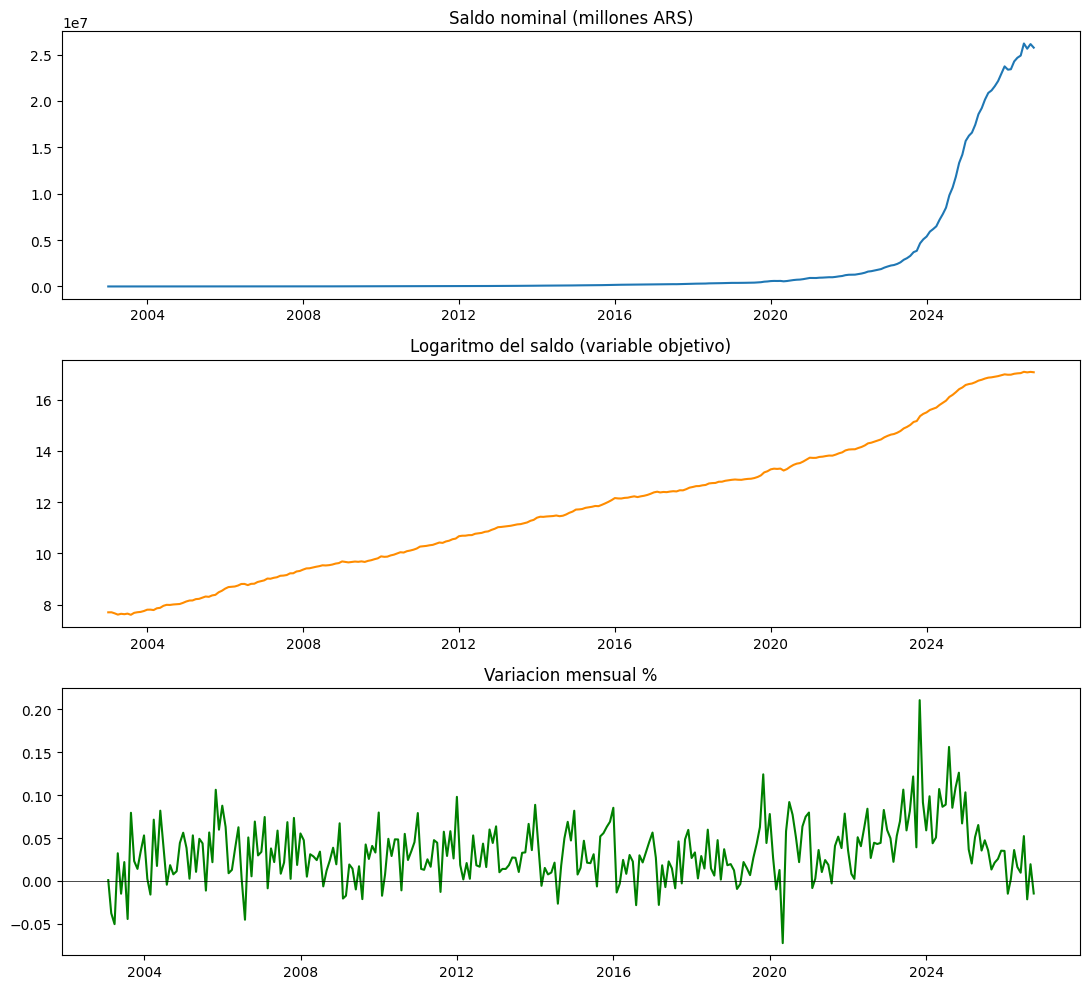


Variacion log promedio por mes (2017+):
mes
1    0.03
2    0.00
3    0.03
4    0.03
5    0.05
6    0.05
7    0.04
8    0.05
9    0.03
10   0.08
11   0.06
12   0.05
Name: var_log, dtype: float64


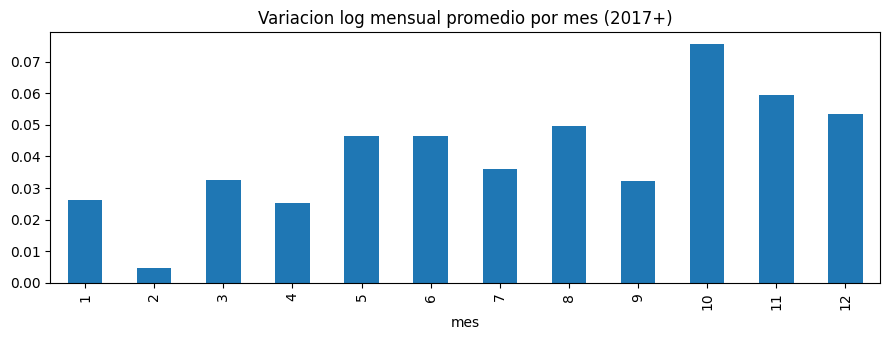

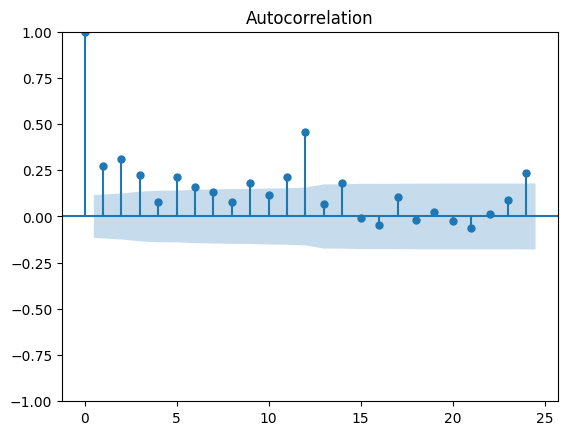

In [7]:
# ---------- 4. GRAFICOS (cerrá cada ventana para ver el siguiente) ----------
fig, ax = plt.subplots(3, 1, figsize=(11, 10))
ax[0].plot(mensual.index, mensual["saldo_tc"])
ax[0].set_title("Saldo nominal (millones ARS)")
ax[1].plot(mensual.index, mensual["log_saldo"], color="darkorange")
ax[1].set_title("Logaritmo del saldo (variable objetivo)")
ax[2].plot(mensual.index, mensual["var_mensual"], color="green")
ax[2].axhline(0, color="k", lw=0.5)
ax[2].set_title("Variacion mensual %")
plt.tight_layout()
plt.savefig("results/grafico_serie.png", dpi=120)
plt.show()

rec = mensual.loc["2017":]
est = rec.groupby("mes")["var_log"].mean()
print("\nVariacion log promedio por mes (2017+):")
print(est)
est.plot(kind="bar", figsize=(9, 3.5), title="Variacion log mensual promedio por mes (2017+)")
plt.tight_layout()
plt.savefig("results/grafico_estacionalidad.png", dpi=120)
plt.show()

plot_acf(mensual["var_log"].dropna(), lags=24)
plt.savefig("results/grafico_acf.png", dpi=120)
plt.show()

## 3. Variables explicativas y control de fuga de información
Series del BCRA: tipo de cambio mayorista de referencia (id 5), tasa BADLAR de bancos privados (id 7) e inflación mensual (id 27, republicada a partir del INDEC). La tasa de política monetaria (ids 160/161) se descartó porque dejó de actualizarse el 10/07/2025.

**Regla de oro:** en cada fecha de pronóstico *t* solo se usa información ya disponible. El IPC entra con rezago de 1 y 2 meses (se publica con demora) y nunca se usan valores futuros.

In [8]:
import requests, time
import numpy as np
import pandas as pd
import urllib3

urllib3.disable_warnings()
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

BASE = "https://api.bcra.gob.ar/estadisticas/v4.0/Monetarias/{}"
def descargar_serie_bcra(id_var, desde="2002-01-01", limit=3000):
    hasta = FECHA_CORTE
    filas, offset = [], 0
    while True:
        params = {"desde": desde, "hasta": hasta, "limit": limit, "offset": offset}
        try:
            r = requests.get(BASE.format(id_var), params=params, timeout=60)
        except requests.exceptions.SSLError:
            r = requests.get(BASE.format(id_var), params=params, timeout=60, verify=False)
        r.raise_for_status()
        data = r.json()
        results = data["results"]
        if results and isinstance(results[0], dict) and "detalle" in results[0]:
            bloque = results[0]["detalle"]
        else:
            bloque = results
        if not bloque:
            break
        filas.extend(bloque)
        total = data.get("metadata", {}).get("resultset", {}).get("count", len(filas))
        offset += limit
        if offset >= total:
            break
        time.sleep(0.5)
    df = pd.DataFrame(filas)[["fecha", "valor"]]
    df["fecha"] = pd.to_datetime(df["fecha"])
    return df.sort_values("fecha").drop_duplicates("fecha").set_index("fecha")["valor"]


def a_mensual(serie):
    try:
        return serie.resample("ME").last()
    except ValueError:
        return serie.resample("M").last()

In [9]:
# ---------- 1. DESCARGA DE VARIABLES MACRO ----------
print("Descargando tipo de cambio mayorista (id 5)...")
tc = descargar_serie_bcra(5)
tc.to_csv("data/bcra_tc_cambio_raw.csv")
print("Descargando BADLAR bancos privados (id 7)...")
badlar = descargar_serie_bcra(7)
badlar.to_csv("data/bcra_badlar_raw.csv")
print("Descargando inflacion mensual (id 27)...")
ipc = descargar_serie_bcra(27)
ipc.to_csv("data/bcra_ipc_raw.csv")

Descargando tipo de cambio mayorista (id 5)...
Descargando BADLAR bancos privados (id 7)...
Descargando inflacion mensual (id 27)...


In [10]:
# ---------- 2. BASE MENSUAL ----------
base = pd.read_csv("data/bcra_tc_mensual.csv", index_col=0, parse_dates=True)
base = base[["saldo_tc", "log_saldo"]]

base["tipo_cambio"] = a_mensual(tc)
base["badlar"] = a_mensual(badlar)
base["ipc_mensual"] = a_mensual(ipc)   # variacion % mensual publicada con demora

print("\nPrimer dato disponible de cada variable:")
for c in ["tipo_cambio", "badlar", "ipc_mensual"]:
    print(f"  {c}: {base[c].first_valid_index().date()}  | nulos en la base: {base[c].isna().sum()}")


Primer dato disponible de cada variable:
  tipo_cambio: 2002-12-31  | nulos en la base: 0
  badlar: 2002-12-31  | nulos en la base: 0
  ipc_mensual: 2002-12-31  | nulos en la base: 1


In [11]:
# ---------- 3. VARIABLES DERIVADAS (solo con informacion pasada) ----------
base["log_tc_cambio"] = np.log(base["tipo_cambio"])
base["var_log_tc_cambio"] = base["log_tc_cambio"].diff()           # depreciacion mensual al cierre del mes de origen
base["var_log_saldo"] = base["log_saldo"].diff()

# Rezagos del objetivo
for k in [1, 2, 3, 12]:
    base[f"log_saldo_lag{k}"] = base["log_saldo"].shift(k)
base["var_log_saldo_lag1"] = base["var_log_saldo"].shift(1)

# IPC con rezago minimo de 1 mes (por demora de publicacion)
base["ipc_lag1"] = base["ipc_mensual"].shift(1)
base["ipc_lag2"] = base["ipc_mensual"].shift(2)

# Calendario
base["mes"] = base.index.month
base["es_diciembre"] = (base["mes"] == 12).astype(int)

In [12]:
# ---------- 4. OBJETIVOS A 1, 2 Y 3 MESES ----------
for h in [1, 2, 3]:
    base[f"y_h{h}"] = base["log_saldo"].shift(-h)

In [13]:
# ---------- 5. CONTROL Y GUARDADO ----------
print("\nUltimas 6 filas de la base:")
print(base[["log_saldo", "tipo_cambio", "badlar", "ipc_mensual", "ipc_lag1", "y_h1", "y_h3"]].tail(6))

print("\nNulos por columna:")
print(base.isna().sum().to_string())

base.to_csv("data/dataset_modelado.csv")
print("\nGuardado: dataset_modelado.csv  | filas:", base.shape[0], "| columnas:", base.shape[1])

# Correlaciones simples con la variacion mensual del saldo (solo exploratorio)
cols = ["var_log_saldo", "var_log_tc_cambio", "badlar", "ipc_mensual", "ipc_lag1"]
print("\nCorrelacion (desde 2017):")
print(base.loc["2017":, cols].corr().round(2).to_string())


Ultimas 6 filas de la base:
            log_saldo  tipo_cambio  badlar  ipc_mensual  ipc_lag1    y_h1    y_h3
fecha                                                                            
2026-04-30    17.0207   1,381.0954 20.8750       2.6000    3.4000 17.0302 17.0595
2026-05-31    17.0302   1,410.2904 20.6250       2.1000    2.6000 17.0812 17.0787
2026-06-30    17.0812   1,483.0198 21.0000       1.9000    2.1000 17.0595 17.0639
2026-07-31    17.0595   1,488.4531 21.6250       2.1000    1.9000 17.0787     NaN
2026-08-31    17.0787   1,509.4686 23.0000       1.7000    2.1000 17.0639     NaN
2026-09-30    17.0639   1,517.5209 22.8125          NaN    1.7000     NaN     NaN

Nulos por columna:
saldo_tc               0
log_saldo              0
tipo_cambio            0
badlar                 0
ipc_mensual            1
log_tc_cambio          0
var_log_tc_cambio      1
var_log_saldo          1
log_saldo_lag1         1
log_saldo_lag2         2
log_saldo_lag3         3
log_saldo_lag12     

## 4. Baselines (reglas simples)
Persistencia, naive estacional y deriva a 6 y 12 meses, evaluados con las mismas métricas y en la misma escala que los modelos. Se reportan tres ventanas: desde 2017, desde 2023 y las últimas 24 fechas de pronóstico.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Variable objetivo: logaritmo del saldo nominal. Las metricas se reportan en pesos nominales
# (se revierte el logaritmo con exp).
df = pd.read_csv("data/dataset_modelado.csv", index_col=0, parse_dates=True)
ls = df["log_saldo"]
d = ls.diff()
HORIZONTES = [1, 2, 3]

In [15]:
def predicciones(h):
    """Para cada fecha de origen t (fin de mes), pronostico del log-saldo en t+h
    usando SOLO informacion disponible en t."""
    out = pd.DataFrame(index=ls.index)
    out["real_log"] = ls.shift(-h)                         # lo que se quiere predecir (t+h)
    out["persistencia"] = ls                               # repite el ultimo saldo
    out["estacional"] = ls.shift(12 - h)                   # mismo mes del anio anterior (t+h-12)
    out["deriva_6m"] = ls + h * d.rolling(6).mean()        # ultimo saldo + h * crecimiento medio 6m
    out["deriva_12m"] = ls + h * d.rolling(12).mean()      # idem con 12m
    return out.dropna()


def metricas(real_log, pred_log):
    y, p = np.exp(real_log), np.exp(pred_log)
    return {
        "MAPE_%": (np.abs(y - p) / y).mean() * 100,
        "MAE": np.abs(y - p).mean(),
        "RMSE": np.sqrt(((y - p) ** 2).mean()),
    }

In [16]:
VENTANAS = {
    "1) Desde 2017": lambda p: p.loc["2017":],
    "2) Desde 2023": lambda p: p.loc["2023":],
    "3) Ultimos 24 origenes": lambda p: p.tail(24),
}
MODELOS = ["persistencia", "estacional", "deriva_6m", "deriva_12m"]

filas = []
preds = {}
for h in HORIZONTES:
    p = predicciones(h)
    preds[h] = p
    for nombre, f in VENTANAS.items():
        sub = f(p)
        for m in MODELOS:
            r = metricas(sub["real_log"], sub[m])
            filas.append({"ventana": nombre, "horizonte": h, "modelo": m, "n_origenes": len(sub), **r})

res = pd.DataFrame(filas)
res.to_csv("results/resultados_baselines.csv", index=False)

In [17]:
print("=== MAPE (%) POR VENTANA, MODELO Y HORIZONTE (meses) ===")
tabla = res.pivot_table(index=["ventana", "modelo"], columns="horizonte", values="MAPE_%")
print(tabla.to_string())

print("\n=== CANTIDAD DE ORIGENES EVALUADOS ===")
print(res.pivot_table(index="ventana", columns="horizonte", values="n_origenes").to_string())

print("\n=== MEJOR BASELINE (menor MAPE) POR VENTANA Y HORIZONTE ===")
mejor = res.loc[res.groupby(["ventana", "horizonte"])["MAPE_%"].idxmin(), ["ventana", "horizonte", "modelo", "MAPE_%"]]
print(mejor.to_string(index=False))

print("\n=== MAPE A SUPERAR PARA CUMPLIR LA MEJORA DE 20% SOBRE PERSISTENCIA ===")
pers = res[res["modelo"] == "persistencia"][["ventana", "horizonte", "MAPE_%"]].copy()
pers["objetivo_(80%)"] = pers["MAPE_%"] * 0.8
print(pers.to_string(index=False))

print("\n=== MAE y RMSE (millones de ARS) - ventana: ultimos 24 origenes ===")
print(res[res["ventana"].str.startswith("3")].pivot_table(index="modelo", columns="horizonte", values=["MAE", "RMSE"]).to_string())

=== MAPE (%) POR VENTANA, MODELO Y HORIZONTE (meses) ===
horizonte                               1     2     3
ventana                modelo                        
1) Desde 2017          deriva_12m    2.51  4.09  5.79
                       deriva_6m     2.49  4.33  6.34
                       estacional   36.82 36.96 37.10
                       persistencia  4.24  7.86 11.44
2) Desde 2023          deriva_12m    2.82  4.73  7.33
                       deriva_6m     2.50  4.35  6.56
                       estacional   49.53 49.64 49.75
                       persistencia  5.53 10.52 15.42
3) Ultimos 24 origenes deriva_12m    2.88  5.16  8.03
                       deriva_6m     2.18  3.83  5.84
                       estacional   43.09 43.09 43.09
                       persistencia  3.57  6.72 10.23

=== CANTIDAD DE ORIGENES EVALUADOS ===
horizonte                   1      2      3
ventana                                    
1) Desde 2017          116.00 115.00 114.00
2) Desde 2023  


Guardado: resultados_baselines.csv y grafico_error_persistencia.png


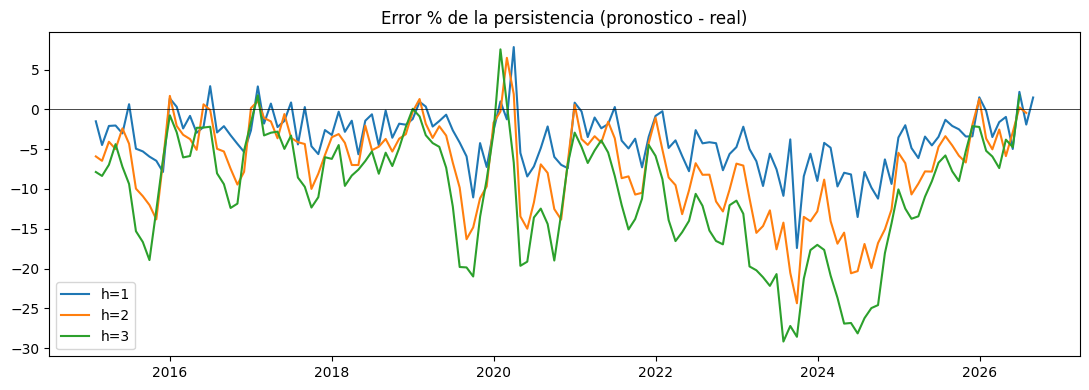

In [18]:
# Grafico: error porcentual de la persistencia en el tiempo
fig, ax = plt.subplots(figsize=(11, 4))
for h in HORIZONTES:
    p = preds[h].loc["2015":]
    err = (np.exp(p["persistencia"]) - np.exp(p["real_log"])) / np.exp(p["real_log"]) * 100
    ax.plot(err.index, err, label=f"h={h}")
ax.axhline(0, color="k", lw=0.5)
ax.set_title("Error % de la persistencia (pronostico - real)")
ax.legend()
plt.tight_layout()
plt.savefig("results/grafico_error_persistencia.png", dpi=120)
print("\nGuardado: resultados_baselines.csv y grafico_error_persistencia.png")

## 5. Modelos y validación walk-forward
SARIMA, Ridge y XGBoost (con *gradient boosting* de scikit-learn como respaldo si XGBoost no está disponible), un modelo directo por horizonte (1, 2 y 3 meses). En cada fecha de origen se reentrena solo con datos cuyo resultado ya era conocido en esa fecha. Tarda unos minutos.

In [19]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from statsmodels.tsa.statespace.sarimax import SARIMAX

try:
    from xgboost import XGBRegressor
    USA_XGBOOST = True
except Exception:
    from sklearn.ensemble import GradientBoostingRegressor
    USA_XGBOOST = False

warnings.filterwarnings("ignore")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

HORIZONTES = [1, 2, 3]
INICIO_EVALUACION = "2017-01-01"
VENTANA_SARIMA = 96   # meses de historia para ajustar el SARIMA en cada origen

In [20]:
# ------------------------------------------------------------------
# 1. DATOS Y VARIABLES (todas calculadas SOLO con informacion disponible en el origen t)
# ------------------------------------------------------------------
df = pd.read_csv("data/dataset_modelado.csv", index_col=0, parse_dates=True)
ls = df["log_saldo"]                  # variable objetivo: log del saldo nominal
g = ls.diff()                         # crecimiento log mensual del saldo (hasta t)
tcg = np.log(df["tipo_cambio"]).diff()

X = pd.DataFrame(index=df.index)
X["g_t"] = g
X["g_l1"] = g.shift(1)
X["g_l2"] = g.shift(2)
X["g_m3"] = g.rolling(3).mean()
X["g_m6"] = g.rolling(6).mean()
X["g_m12"] = g.rolling(12).mean()
X["ipc_lag1"] = df["ipc_mensual"].shift(1)      # IPC publicado: rezago minimo 1 mes
X["ipc_lag2"] = df["ipc_mensual"].shift(2)
X["tc_g_t"] = tcg                                # depreciacion del mes de origen (cierre)
X["tc_g_m3"] = tcg.rolling(3).mean()
X["badlar_t"] = df["badlar"]                     # tasa al cierre del mes de origen
X["mes_sin"] = np.sin(2 * np.pi * df.index.month / 12)
X["mes_cos"] = np.cos(2 * np.pi * df.index.month / 12)
FEATURES = list(X.columns)
print("Variables permitidas en los modelos:", FEATURES)

# Objetivo directo por horizonte: crecimiento log acumulado entre t y t+h
Z = {h: ls.shift(-h) - ls for h in HORIZONTES}


def nuevo_ridge():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 12)))


def nuevo_boosting():
    if USA_XGBOOST:
        return XGBRegressor(n_estimators=200, max_depth=2, learning_rate=0.05, subsample=0.8,
                            colsample_bytree=0.8, reg_lambda=5.0, random_state=0, verbosity=0)
    return GradientBoostingRegressor(n_estimators=200, max_depth=2, learning_rate=0.05,
                                     subsample=0.8, random_state=0)


NOMBRE_BOOST = "xgboost" if USA_XGBOOST else "gradient_boosting"
print("Algoritmo de boosting usado:", NOMBRE_BOOST)


def pronostico_sarima(pos):
    """Ajusta un SARMA sobre el crecimiento log mensual (hasta t) y devuelve el crecimiento acumulado a 1..3 meses."""
    serie = g.iloc[max(1, pos - VENTANA_SARIMA + 1): pos + 1].dropna()
    serie.index = pd.DatetimeIndex(serie.index).to_period("M")
    try:
        res = SARIMAX(serie, order=(1, 0, 1), seasonal_order=(1, 0, 0, 12), trend="c").fit(disp=False, maxiter=100)
    except Exception:
        res = SARIMAX(serie, order=(1, 0, 1), trend="c").fit(disp=False, maxiter=100)
    return res.forecast(steps=3).cumsum().values

Variables permitidas en los modelos: ['g_t', 'g_l1', 'g_l2', 'g_m3', 'g_m6', 'g_m12', 'ipc_lag1', 'ipc_lag2', 'tc_g_t', 'tc_g_m3', 'badlar_t', 'mes_sin', 'mes_cos']
Algoritmo de boosting usado: xgboost


In [21]:
# ------------------------------------------------------------------
# 2. WALK-FORWARD: en cada origen t se reentrena con datos hasta t (objetivo ya conocido en t)
# ------------------------------------------------------------------
origenes = df.index[df.index >= INICIO_EVALUACION]
filas = []
print(f"\nEvaluando {len(origenes)} origenes (walk-forward, ventana expansiva)... puede tardar unos minutos")

for n, t in enumerate(origenes, 1):
    pos = df.index.get_loc(t)
    if n % 20 == 0:
        print(f"  origen {n}/{len(origenes)}: {t.date()}")
    base_t = ls.iloc[pos]

    try:
        z_sarima = pronostico_sarima(pos)
    except Exception:
        z_sarima = [np.nan] * 3

    for h in HORIZONTES:
        if pos + h >= len(df):
            continue                                  # todavia no hay dato real para evaluar
        real = ls.iloc[pos + h]
        preds = {
            "persistencia": base_t,
            "estacional": ls.iloc[pos + h - 12],
            "deriva_6m": base_t + h * g.iloc[pos - 5: pos + 1].mean(),
            "deriva_12m": base_t + h * g.iloc[pos - 11: pos + 1].mean(),
            "sarima": base_t + z_sarima[h - 1],
        }
        # entrenamiento: solo filas cuyo objetivo (s+h) ya era conocido en t  ->  s <= t-h
        idx_tr = df.index[: pos - h + 1]
        Xtr = X.loc[idx_tr].dropna()
        ytr = Z[h].loc[Xtr.index]
        xt = X.iloc[[pos]]
        if len(Xtr) >= 24 and not xt.isna().any(axis=None):
            preds["ridge"] = base_t + nuevo_ridge().fit(Xtr, ytr).predict(xt)[0]
            preds[NOMBRE_BOOST] = base_t + nuevo_boosting().fit(Xtr, ytr).predict(xt)[0]
        for m, p in preds.items():
            filas.append({"origen": t, "h": h, "modelo": m, "pred_log": p, "real_log": real})

P = pd.DataFrame(filas).dropna()
P.to_csv("results/predicciones_modelos.csv", index=False)


Evaluando 117 origenes (walk-forward, ventana expansiva)... puede tardar unos minutos
  origen 20/117: 2018-08-31
  origen 40/117: 2020-04-30
  origen 60/117: 2021-12-31
  origen 80/117: 2023-08-31
  origen 100/117: 2025-04-30


In [22]:
# ------------------------------------------------------------------
# 3. METRICAS EN PESOS NOMINALES (se revierte el logaritmo)
# ------------------------------------------------------------------
def metricas(sub):
    y, p = np.exp(sub["real_log"]), np.exp(sub["pred_log"])
    return pd.Series({"MAPE_%": (np.abs(y - p) / y).mean() * 100,
                      "MAE": np.abs(y - p).mean(),
                      "RMSE": np.sqrt(((y - p) ** 2).mean()),
                      "n": len(sub)})


VENTANAS = {
    "1) Desde 2017": lambda s: s,
    "2) Desde 2023": lambda s: s[s["origen"] >= "2023-01-01"],
    "3) Ultimos 24 origenes": lambda s: s[s["origen"].isin(sorted(s["origen"].unique())[-24:])],
}

# Para comparar justo: mismos origenes para todos los modelos en cada horizonte
filas_res = []
for h in HORIZONTES:
    Ph = P[P["h"] == h]
    comunes = set.intersection(*[set(Ph[Ph["modelo"] == m]["origen"]) for m in Ph["modelo"].unique()])
    Ph = Ph[Ph["origen"].isin(comunes)]
    for nombre, f in VENTANAS.items():
        for m, sub in f(Ph).groupby("modelo"):
            r = metricas(sub)
            filas_res.append({"ventana": nombre, "horizonte": h, "modelo": m, **r})
R = pd.DataFrame(filas_res)
R.to_csv("results/resultados_modelos.csv", index=False)

orden = ["persistencia", "estacional", "deriva_6m", "deriva_12m", "sarima", "ridge", NOMBRE_BOOST]
tabla = R.pivot_table(index=["ventana", "modelo"], columns="horizonte", values="MAPE_%")
tabla = tabla.reindex([(v, m) for v in sorted(VENTANAS) for m in orden if (v, m) in tabla.index])
print("\n=== MAPE (%) POR VENTANA, MODELO Y HORIZONTE ===")
print(tabla.to_string())

print("\n=== MEJORA DE MAPE (%) RESPECTO DE LA PERSISTENCIA y DEL MEJOR BASELINE (positivo = mejor) ===")
base_names = ["persistencia", "estacional", "deriva_6m", "deriva_12m"]
filas_m = []
for v in VENTANAS:
    for h in HORIZONTES:
        sub = R[(R["ventana"] == v) & (R["horizonte"] == h)].set_index("modelo")["MAPE_%"]
        mejor_b = sub[base_names].min()
        for m in ["sarima", "ridge", NOMBRE_BOOST]:
            if m in sub.index:
                filas_m.append({"ventana": v, "horizonte": h, "modelo": m, "MAPE_%": sub[m],
                                "mejora_vs_persistencia_%": (1 - sub[m] / sub["persistencia"]) * 100,
                                "mejora_vs_mejor_baseline_%": (1 - sub[m] / mejor_b) * 100})
print(pd.DataFrame(filas_m).to_string(index=False))

print("\n=== MAE y RMSE (millones de ARS) - ultimos 24 origenes ===")
print(R[R["ventana"].str.startswith("3")].pivot_table(index="modelo", columns="horizonte", values=["MAE", "RMSE"]).to_string())


=== MAPE (%) POR VENTANA, MODELO Y HORIZONTE ===
horizonte                               1     2     3
ventana                modelo                        
1) Desde 2017          persistencia  4.24  7.86 11.44
                       estacional   36.82 36.96 37.10
                       deriva_6m     2.49  4.33  6.34
                       deriva_12m    2.51  4.09  5.79
                       sarima        2.35  3.92  5.33
                       ridge         2.56  4.31  5.95
                       xgboost       2.38  3.84  5.38
2) Desde 2023          persistencia  5.53 10.52 15.42
                       estacional   49.53 49.64 49.75
                       deriva_6m     2.50  4.35  6.56
                       deriva_12m    2.82  4.73  7.33
                       sarima        2.67  4.38  6.61
                       ridge         3.01  5.48  7.97
                       xgboost       2.73  4.57  6.72
3) Ultimos 24 origenes persistencia  3.57  6.72 10.23
                       estaciona

In [23]:
# ------------------------------------------------------------------
# 4. INTERPRETABILIDAD: que variables usan los modelos (ajuste final con todos los datos)
# ------------------------------------------------------------------
print("\n=== VARIABLES MAS IMPORTANTES (ajuste con todos los datos disponibles) ===")
for h in [1, 3]:
    Xtr = X.dropna()
    Xtr = Xtr.loc[Xtr.index.intersection(Z[h].dropna().index)]
    ytr = Z[h].loc[Xtr.index]
    b = nuevo_boosting().fit(Xtr, ytr)
    imp = pd.Series(b.feature_importances_, index=FEATURES).sort_values(ascending=False)
    print(f"\n{NOMBRE_BOOST} - horizonte {h}: importancia relativa")
    print((imp.head(6) * 100).round(1).to_string())
    rg = nuevo_ridge().fit(Xtr, ytr)
    coef = pd.Series(rg[-1].coef_, index=FEATURES)
    print(f"Ridge - horizonte {h}: coeficientes mas grandes (variables estandarizadas)")
    print(coef.reindex(coef.abs().sort_values(ascending=False).index).head(6).map(lambda v: f"{v:.4f}").to_string())


=== VARIABLES MAS IMPORTANTES (ajuste con todos los datos disponibles) ===

xgboost - horizonte 1: importancia relativa
g_m12      13.50
mes_sin    13.00
g_m6       11.20
ipc_lag2   11.10
g_m3        8.00
mes_cos     6.80
Ridge - horizonte 1: coeficientes mas grandes (variables estandarizadas)
mes_sin     -0.0058
g_m12        0.0042
badlar_t     0.0024
ipc_lag1     0.0024
g_l1         0.0022
ipc_lag2     0.0018

xgboost - horizonte 3: importancia relativa
g_m12      21.00
mes_sin    16.10
g_m6       13.20
ipc_lag1   10.30
ipc_lag2    9.90
mes_cos     5.80
Ridge - horizonte 3: coeficientes mas grandes (variables estandarizadas)
mes_sin     -0.0196
g_m12        0.0137
mes_cos     -0.0122
ipc_lag1     0.0086
ipc_lag2     0.0084
badlar_t     0.0072



Guardado: predicciones_modelos.csv, resultados_modelos.csv y grafico_mape_modelos.png


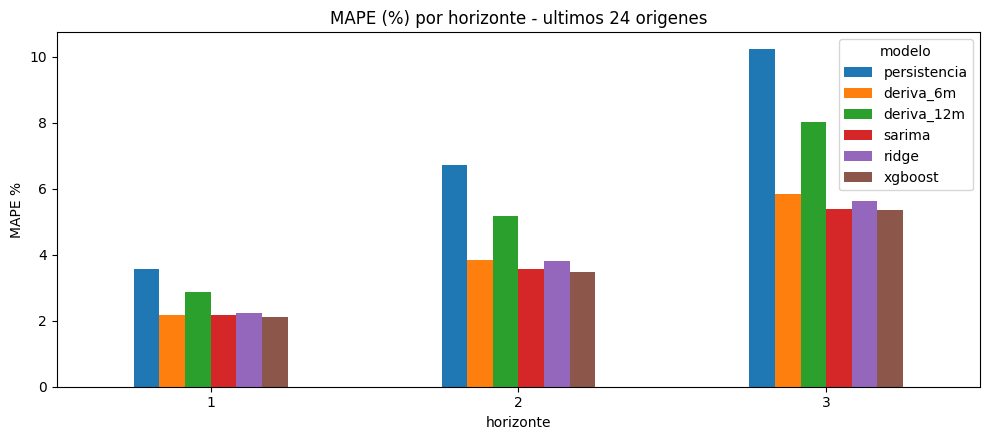

In [24]:
# ------------------------------------------------------------------
# 5. GRAFICO
# ------------------------------------------------------------------
g24 = R[R["ventana"].str.startswith("3")].pivot_table(index="horizonte", columns="modelo", values="MAPE_%")
g24 = g24[[m for m in orden if m in g24.columns and m != "estacional"]]
ax = g24.plot(kind="bar", figsize=(10, 4.5), title="MAPE (%) por horizonte - ultimos 24 origenes")
ax.set_ylabel("MAPE %")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("results/grafico_mape_modelos.png", dpi=120)
print("\nGuardado: predicciones_modelos.csv, resultados_modelos.csv y grafico_mape_modelos.png")

## 6. Pronóstico final, valor para el negocio y prueba de Diebold-Mariano
Pronóstico SARIMA de octubre a diciembre de 2026 con banda de error empírica del 80%, el error típico traducido a pesos y una prueba estadística para saber si SARIMA es realmente mejor que las reglas simples.

**Conclusión (corrida de octubre de 2026):** SARIMA y XGBoost están empatados; SARIMA supera de forma significativa a la persistencia en el período largo, pero no hay diferencia significativa frente a la deriva a 6 meses. El crecimiento del saldo tiene mucha inercia y las variables macro aportan poco.

In [25]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.statespace.sarimax import SARIMAX

warnings.filterwarnings("ignore")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

HORIZONTES = [1, 2, 3]
VENTANA_SARIMA = 96
N_ERRORES_BANDA = 36      # ultimos origenes usados para estimar la banda de error

df = pd.read_csv("data/dataset_modelado.csv", index_col=0, parse_dates=True)
ls = df["log_saldo"]
g = ls.diff()
P = pd.read_csv("results/predicciones_modelos.csv", parse_dates=["origen"])

In [26]:
# ------------------------------------------------------------------
# 1. PRONOSTICO FINAL (origen = ultimo mes completo)
# ------------------------------------------------------------------
pos = len(df) - 1
origen = df.index[pos]
serie = g.iloc[max(1, pos - VENTANA_SARIMA + 1): pos + 1].dropna()
serie.index = pd.DatetimeIndex(serie.index).to_period("M")
try:
    res = SARIMAX(serie, order=(1, 0, 1), seasonal_order=(1, 0, 0, 12), trend="c").fit(disp=False, maxiter=100)
except Exception:
    res = SARIMAX(serie, order=(1, 0, 1), trend="c").fit(disp=False, maxiter=100)
z = res.forecast(steps=3).cumsum().values
base_log = ls.iloc[pos]
saldo_actual = np.exp(base_log)

deriva6 = g.iloc[pos - 5: pos + 1].mean()

filas = []
for h in HORIZONTES:
    # Banda de error empirica: cuantiles de los errores reales del SARIMA en los ultimos origenes (escala log)
    e = P[(P["modelo"] == "sarima") & (P["h"] == h)].sort_values("origen").tail(N_ERRORES_BANDA)
    err = (e["real_log"] - e["pred_log"]).values
    q10, q90 = np.quantile(err, [0.10, 0.90])
    pred = base_log + z[h - 1]
    mape_h = (np.abs(np.exp(e["real_log"]) - np.exp(e["pred_log"])) / np.exp(e["real_log"])).mean() * 100
    fecha = (origen + pd.offsets.MonthEnd(h)).date()
    filas.append({
        "mes_pronosticado": fecha, "horizonte": h,
        "pronostico_sarima": np.exp(pred), "banda_inf_80%": np.exp(pred + q10), "banda_sup_80%": np.exp(pred + q90),
        "pronostico_deriva_6m": np.exp(base_log + h * deriva6),
        "var_vs_ultimo_%": (np.exp(pred) / saldo_actual - 1) * 100,
        "MAPE_historico_%": mape_h,
    })
F = pd.DataFrame(filas)
F.to_csv("results/pronostico_final.csv", index=False)

print(f"=== PRONOSTICO FINAL (origen: {origen.date()}, saldo actual: {saldo_actual:,.0f} millones de ARS) ===")
print(F.to_string(index=False))
print("\nParametros del SARIMA ajustado:")
print(res.params.round(4).to_string())

=== PRONOSTICO FINAL (origen: 2026-09-30, saldo actual: 25,749,986 millones de ARS) ===
mes_pronosticado  horizonte  pronostico_sarima  banda_inf_80%  banda_sup_80%  pronostico_deriva_6m  var_vs_ultimo_%  MAPE_historico_%
      2026-10-31          1      26,059,201.20  25,088,084.41  26,869,604.19         26,006,111.39             1.20              2.60
      2026-11-30          2      26,489,013.11  24,942,010.15  28,093,780.13         26,264,784.36             2.87              4.18
      2026-12-31          3      26,978,751.86  24,748,002.84  29,691,218.81         26,526,030.26             4.77              6.24

Parametros del SARIMA ajustado:
intercept    0.00
ar.L1        0.90
ma.L1       -0.65
ar.S.L12     0.23
sigma2       0.00


In [27]:
# ------------------------------------------------------------------
# 2. VALOR DE NEGOCIO: error esperado en pesos
# ------------------------------------------------------------------
print("\n=== VALOR PARA EL NEGOCIO: error tipico esperado del pronostico (ultimos 24 origenes) ===")
for h in HORIZONTES:
    e = P[(P["modelo"] == "sarima") & (P["h"] == h)].sort_values("origen").tail(24)
    mae = np.abs(np.exp(e["real_log"]) - np.exp(e["pred_log"])).mean()
    print(f"  h={h}: error absoluto medio = {mae:,.0f} millones de ARS  (~{mae / saldo_actual * 100:.1f}% del saldo actual; {mae/1e6:.2f} billones)")


=== VALOR PARA EL NEGOCIO: error tipico esperado del pronostico (ultimos 24 origenes) ===
  h=1: error absoluto medio = 460,934 millones de ARS  (~1.8% del saldo actual; 0.46 billones)
  h=2: error absoluto medio = 737,715 millones de ARS  (~2.9% del saldo actual; 0.74 billones)
  h=3: error absoluto medio = 1,133,671 millones de ARS  (~4.4% del saldo actual; 1.13 billones)


In [28]:
# ------------------------------------------------------------------
# 3. TEST DE DIEBOLD-MARIANO: SARIMA vs deriva 6m (y vs persistencia)
# ------------------------------------------------------------------
def dm_test(e1, e2, h):
    d = e1 ** 2 - e2 ** 2
    n = len(d)
    dbar = d.mean()
    s = np.mean((d - dbar) ** 2)
    for k in range(1, h):
        s += 2 * np.mean((d[k:] - dbar) * (d[:-k] - dbar))
    var = s / n
    if var <= 0:
        return np.nan, np.nan, dbar
    dm = dbar / np.sqrt(var)
    dm *= np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)   # correccion de Harvey et al.
    p = 2 * (1 - stats.t.cdf(abs(dm), n - 1))
    return dm, p, dbar


print("\n=== TEST DE DIEBOLD-MARIANO (error cuadratico en escala log; p<0.05 = diferencia significativa) ===")
filas_dm = []
for h in HORIZONTES:
    W = P[P["h"] == h].pivot_table(index="origen", columns="modelo", values="pred_log")
    real = P[P["h"] == h].drop_duplicates("origen").set_index("origen")["real_log"]
    W = W.join(real).dropna().sort_index()
    for nombre, sub in [("Desde 2017", W), ("Ultimos 24 origenes", W.tail(24))]:
        for rival in ["deriva_6m", "persistencia"]:
            e1 = (sub["real_log"] - sub["sarima"]).values
            e2 = (sub["real_log"] - sub[rival]).values
            dm, p, dbar = dm_test(e1, e2, h)
            filas_dm.append({"ventana": nombre, "horizonte": h, "SARIMA_vs": rival, "n": len(sub),
                             "estadistico_DM": dm, "p_valor": p,
                             "resultado": "SARIMA mejor" if dbar < 0 else "rival mejor"})
DM = pd.DataFrame(filas_dm)
DM.to_csv("results/test_diebold_mariano.csv", index=False)
print(DM.to_string(index=False))


=== TEST DE DIEBOLD-MARIANO (error cuadratico en escala log; p<0.05 = diferencia significativa) ===
            ventana  horizonte    SARIMA_vs   n  estadistico_DM  p_valor    resultado
         Desde 2017          1    deriva_6m 116           -0.90     0.37 SARIMA mejor
         Desde 2017          1 persistencia 116           -6.38     0.00 SARIMA mejor
Ultimos 24 origenes          1    deriva_6m  24           -0.69     0.49 SARIMA mejor
Ultimos 24 origenes          1 persistencia  24           -1.88     0.07 SARIMA mejor
         Desde 2017          2    deriva_6m 115           -0.91     0.37 SARIMA mejor
         Desde 2017          2 persistencia 115           -4.41     0.00 SARIMA mejor
Ultimos 24 origenes          2    deriva_6m  24           -0.54     0.60 SARIMA mejor
Ultimos 24 origenes          2 persistencia  24           -1.50     0.15 SARIMA mejor
         Desde 2017          3    deriva_6m 114           -1.04     0.30 SARIMA mejor
         Desde 2017          3 persiste


Guardado: pronostico_final.csv, test_diebold_mariano.csv, grafico_pronostico.png, grafico_real_vs_pronostico.png


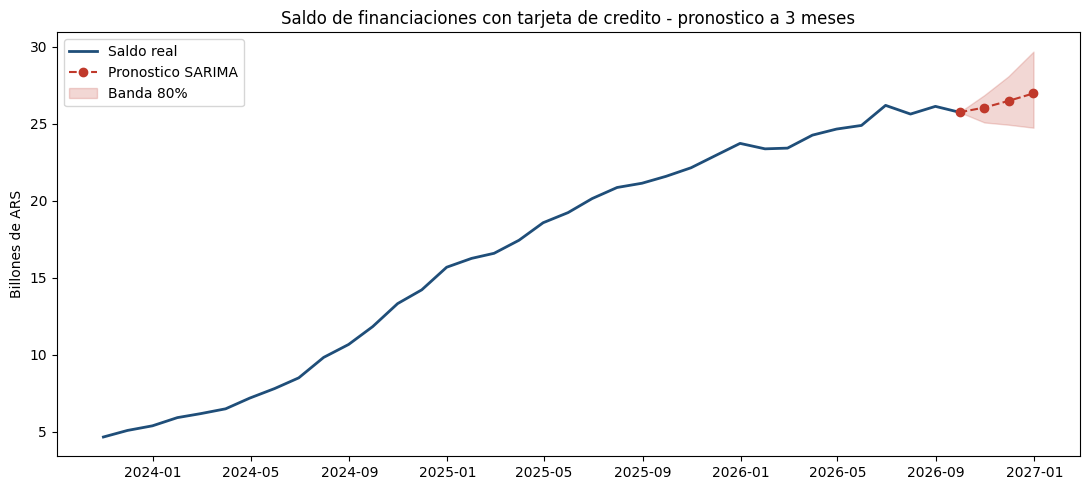

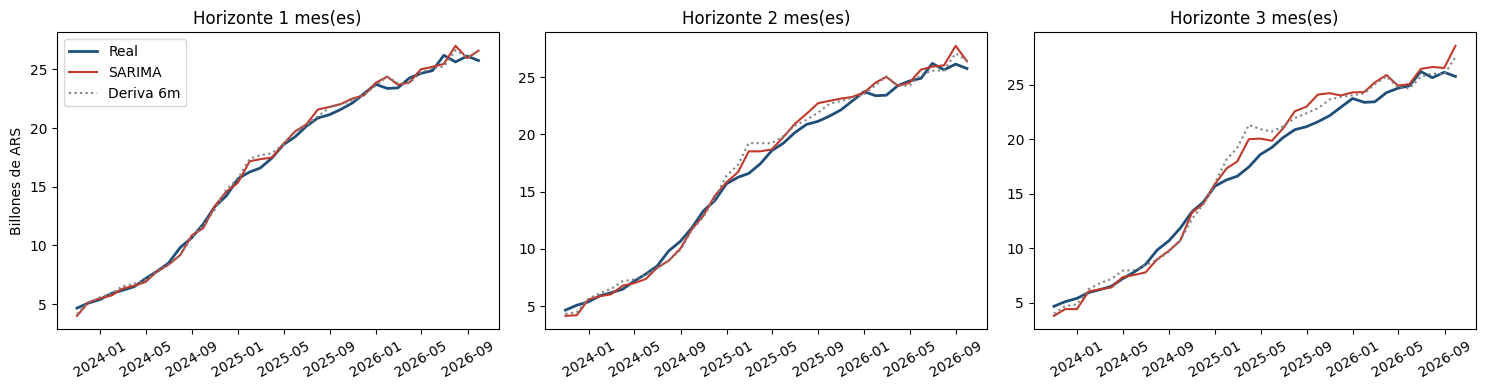

In [29]:
# ------------------------------------------------------------------
# 4. GRAFICOS PARA EL INFORME
# ------------------------------------------------------------------
hist = np.exp(ls.tail(36)) / 1e6
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(hist.index, hist.values, label="Saldo real", color="#1f4e79", lw=2)
fechas = [origen] + [origen + pd.offsets.MonthEnd(h) for h in HORIZONTES]
centro = [saldo_actual / 1e6] + list(F["pronostico_sarima"] / 1e6)
inf = [saldo_actual / 1e6] + list(F["banda_inf_80%"] / 1e6)
sup = [saldo_actual / 1e6] + list(F["banda_sup_80%"] / 1e6)
ax.plot(fechas, centro, "o--", color="#c0392b", label="Pronostico SARIMA")
ax.fill_between(fechas, inf, sup, color="#c0392b", alpha=0.2, label="Banda 80%")
ax.set_title("Saldo de financiaciones con tarjeta de credito - pronostico a 3 meses")
ax.set_ylabel("Billones de ARS")
ax.legend()
plt.tight_layout()
plt.savefig("results/grafico_pronostico.png", dpi=130)

fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, h in zip(axs, HORIZONTES):
    W = P[(P["h"] == h) & (P["modelo"].isin(["sarima", "deriva_6m"]))].pivot_table(index="origen", columns="modelo", values="pred_log")
    real = P[P["h"] == h].drop_duplicates("origen").set_index("origen")["real_log"]
    W = W.join(real).dropna().tail(36)
    idx = W.index + pd.offsets.MonthEnd(h)
    ax.plot(idx, np.exp(W["real_log"]) / 1e6, label="Real", color="#1f4e79", lw=2)
    ax.plot(idx, np.exp(W["sarima"]) / 1e6, label="SARIMA", color="#c0392b")
    ax.plot(idx, np.exp(W["deriva_6m"]) / 1e6, label="Deriva 6m", color="gray", ls=":")
    ax.set_title(f"Horizonte {h} mes(es)")
    ax.tick_params(axis="x", rotation=30)
axs[0].set_ylabel("Billones de ARS")
axs[0].legend()
plt.tight_layout()
plt.savefig("results/grafico_real_vs_pronostico.png", dpi=130)

print("\nGuardado: pronostico_final.csv, test_diebold_mariano.csv, grafico_pronostico.png, grafico_real_vs_pronostico.png")

## Anexo: búsqueda de series en el catálogo del BCRA (opcional)
Permite verificar los `idVariable` usados (tipo de cambio, tasas e inflación).

In [30]:
import requests
import pandas as pd
import urllib3

urllib3.disable_warnings()
URL = "https://api.bcra.gob.ar/estadisticas/v4.0/monetarias"

try:
    r = requests.get(URL, params={"limit": 3000}, timeout=60)
except requests.exceptions.SSLError:
    r = requests.get(URL, params={"limit": 3000}, timeout=60, verify=False)
r.raise_for_status()
data = r.json()

filas = data["results"]
cat = pd.DataFrame(filas)
print("Columnas del catalogo:", list(cat.columns))
print("Series en el catalogo:", len(cat))
cat.to_csv("data/catalogo_bcra.csv", index=False)

col_desc = "descripcion" if "descripcion" in cat.columns else cat.columns[1]
claves = ["cambio", "política monetaria", "politica monetaria", "inflación", "inflacion", "IPC", "BADLAR"]

pd.set_option("display.width", 250)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 500)

for k in claves:
    m = cat[cat[col_desc].str.contains(k, case=False, na=False)]
    if len(m):
        print(f"\n=== Series que contienen '{k}' ({len(m)}) ===")
        cols = [c for c in ["idVariable", col_desc, "periodicidad", "ultFechaInformada"] if c in cat.columns]
        print(m[cols].to_string(index=False))

Columnas del catalogo: ['idVariable', 'descripcion', 'categoria', 'tipoSerie', 'periodicidad', 'unidadExpresion', 'moneda', 'primerFechaInformada', 'ultFechaInformada', 'ultValorInformado']
Series en el catalogo: 1610

=== Series que contienen 'cambio' (6) ===
 idVariable                                                                 descripcion periodicidad ultFechaInformada
          4                                Tipo de cambio minorista (promedio vendedor)            D        2026-10-09
          5                                      Tipo de cambio mayorista de referencia            D        2026-10-09
         84                                        Tipo de cambio de valuación contable            D        2026-10-06
       1602 Tipo de cambio para valuación de activos y pasivos de entidades financieras            D        2002-03-01
       1603 Tipo de cambio para valuación de activos y pasivos de entidades financieras            D        2002-03-01
       1604              

## Limitaciones y consideraciones éticas
- La serie es agregada para todo el sistema financiero: no permite diferenciar entidad, segmento ni rubro.
- Hay cambios de régimen por la inflación; la evaluación en el régimen actual cuenta con pocas fechas (24).
- El saldo es nominal: las decisiones en términos reales requieren un IPC oportuno.
- Los datos son públicos y agregados; no contienen información personal. El modelo **no debe usarse para decisiones de crédito sobre personas**.